# Case 4 – Part F: Test Evaluation and Error Analysis

Category: **Sizing & Fit** (positive = review mentions sizing or fit); labels = `final_label` in `Case4_Labeled.csv`.
Same setup as `case4_knn.ipynb`: three TF-IDF feature sets, k ∈ {1, 3, 5} × cosine/euclidean, 80/20 stratified split (`random_state=42`), 5-fold CV scored by macro-F1.
Interpretation is in `F_section_for_report.docx`.

## Load data and split

In [1]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
df = pd.read_csv("Case4_Labeled.csv").dropna(subset=["final_label"])
df["clean_text"] = df["clean_text"].fillna("").astype(str)
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)
df["topic_text"] = df["topic_tokens"].apply(lambda s: " ".join(ast.literal_eval(s)))
y = df["final_label"].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.20, random_state=SEED, stratify=y)
print(f"Train: {len(X_train)} ({y_train.sum()} positive) | Test: {len(X_test)} ({y_test.sum()} positive)")

Train: 160 (41 positive) | Test: 40 (10 positive)


## Best configuration per feature set + test metrics

Metrics are for the positive class. Only 25% of reviews are positive, so accuracy is compared with the all-negative baseline.

In [2]:
FEATURE_SETS = {
    "TF-IDF unigrams (clean text)":       ("clean_text", (1, 1)),
    "TF-IDF uni+bigrams (clean text)":    ("clean_text", (1, 2)),
    "TF-IDF unigrams (LDA topic tokens)": ("topic_text", (1, 1)),
}
FINAL_MODEL = "TF-IDF unigrams (LDA topic tokens)"   # best CV macro-F1
param_grid = {"knn__n_neighbors": [1, 3, 5], "knn__metric": ["cosine", "euclidean"]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rows, models = [], {}
for name, (col, ngrams) in FEATURE_SETS.items():
    pipe = Pipeline([("vec", TfidfVectorizer(ngram_range=ngrams, min_df=2, max_df=0.9, sublinear_tf=True)),
                     ("knn", KNeighborsClassifier(algorithm="brute"))])
    gs = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro").fit(X_train[col], y_train)
    y_hat = gs.predict(X_test[col])
    models[name] = (gs, col)
    rows.append({"feature set": name,
                 "best k / metric": f"{gs.best_params_['knn__n_neighbors']} / {gs.best_params_['knn__metric']}",
                 "CV macro-F1": gs.best_score_,
                 "precision": precision_score(y_test, y_hat), "recall": recall_score(y_test, y_hat),
                 "F1": f1_score(y_test, y_hat), "accuracy": accuracy_score(y_test, y_hat)})

print(f"All-negative baseline accuracy: {1 - y_test.mean():.3f}")
pd.DataFrame(rows).round(3)

All-negative baseline accuracy: 0.750


,feature set,best k / metric,CV macro-F1,precision,recall,F1,accuracy
0,TF-IDF unigrams (clean text),1 / cosine,0.673,0.800,0.4,0.533,0.825
1,TF-IDF uni+bigrams (clean text),5 / cosine,0.677,0.750,0.3,0.429,0.800
2,TF-IDF unigrams (LDA topic tokens),3 / cosine,0.757,0.571,0.4,0.471,0.775


## Confusion matrix (final model)

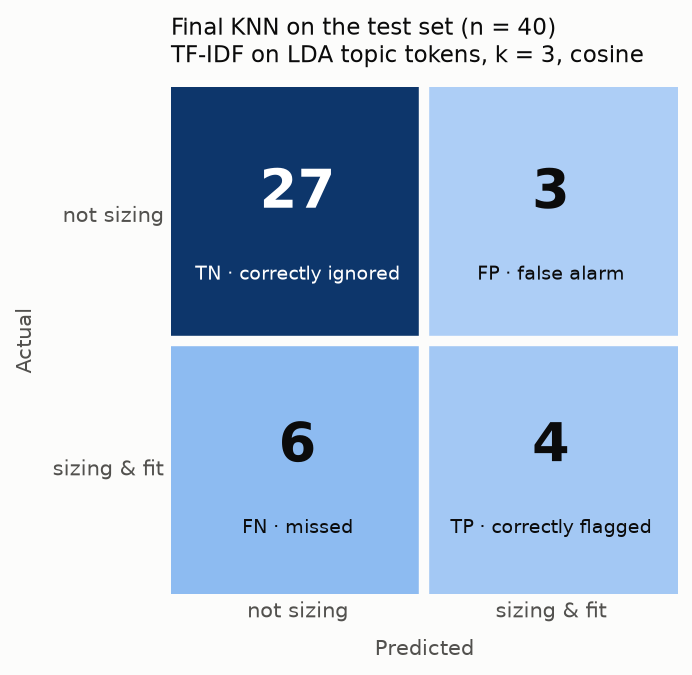

In [3]:
gs_final, col_final = models[FINAL_MODEL]
y_pred = gs_final.predict(X_test[col_final])
cm = confusion_matrix(y_test, y_pred)

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
tags = [["TN · correctly ignored", "FP · false alarm"], ["FN · missed", "TP · correctly flagged"]]
classes = ["not sizing", "sizing & fit"]

fig, ax = plt.subplots(figsize=(5.4, 4.6), dpi=150, facecolor="#fcfcfb")
ax.imshow(cm, cmap=blues, vmin=0, vmax=cm.max())
for i in range(2):
    for j in range(2):
        ink = "#ffffff" if cm[i, j] > cm.max() / 2 else "#0b0b0b"
        ax.text(j, i - 0.08, cm[i, j], ha="center", va="center", fontsize=26, fontweight="bold", color=ink)
        ax.text(j, i + 0.24, tags[i][j], ha="center", va="center", fontsize=9, color=ink)
ax.set_xticks([0, 1], classes)
ax.set_yticks([0, 1], classes)
ax.set_xlabel("Predicted", color="#52514e", labelpad=8)
ax.set_ylabel("Actual", color="#52514e", labelpad=8)
ax.tick_params(length=0, labelcolor="#52514e", labelsize=10)
ax.set_xticks([0.5], minor=True)
ax.set_yticks([0.5], minor=True)
ax.tick_params(which="minor", length=0)
ax.grid(which="minor", color="#fcfcfb", linewidth=5)   # gap between cells
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Final KNN on the test set (n = 40)\nTF-IDF on LDA topic tokens, k = 3, cosine",
             loc="left", fontsize=11, color="#0b0b0b", pad=12)
plt.tight_layout()
plt.show()

## Error analysis

KNN has no coefficients, so each misclassified test review is printed with its 3 nearest training reviews.
`vote share` = share of those neighbours that are positive (predict 1 if ≥ 2 of 3).

In [4]:
vec = gs_final.best_estimator_.named_steps["vec"]
knn = gs_final.best_estimator_.named_steps["knn"]
Xte_vec = vec.transform(X_test[col_final])
dist, idx = knn.kneighbors(Xte_vec)
vote_share = knn.predict_proba(Xte_vec)[:, 1]
vocab = set(vec.vocabulary_)
test, train_text = X_test.reset_index(drop=True), X_train["review_text"].values

wrong = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(wrong)} ({(y_test[wrong] == 1).sum()} FN, {(y_test[wrong] == 0).sum()} FP)")
for i in wrong:
    dropped = [w for w in test.loc[i, "topic_text"].split() if w not in vocab]
    print("\n" + "-" * 100)
    print(f"[{'FN' if y_test[i] == 1 else 'FP'}] id={test.loc[i, 'reviewer_id']} | vote share={vote_share[i]:.2f}")
    print("TEXT:", test.loc[i, "review_text"])
    print("Not in vocabulary:", ", ".join(dropped) or "-")
    for j, d in zip(idx[i], dist[i]):
        print(f"   NN [y={y_train[j]}, d={d:.2f}] {train_text[j][:90]}")

Misclassified: 9 (6 FN, 3 FP)

----------------------------------------------------------------------------------------------------
[FN] id=129852 | vote share=0.00
TEXT: Every year I give my husband a shirt or sweater that he "can" wear on Christmas.He will love the long sleeve tee shirt that I will give him this year!His favorite song of all time is Radar Love and I got the shirt in red.It's a nice weight tee shirt and extra roomy. Very fast delivery.
Not in vocabulary: husband, sweater, sleeve, song, radar, weight, extra, roomy
   NN [y=0, d=0.69] I love my tee shirt the one thing I have a problem with is a 13 dollar shirt winds up to b
   NN [y=0, d=0.72] Fast delivery and great quality t-shirt.
   NN [y=0, d=0.72] Love that I'm supporting local artists. Tee is super soft as stated, with a great design. 

----------------------------------------------------------------------------------------------------
[FN] id=74752 | vote share=0.33
TEXT: The only problem I have is with the size